# Лабораторная работа 2. Классификация. Нейронные сети

**Датасет:** [Credit Card customers — Kaggle](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers).  
**Задача:** прогноз оттока клиента кредитной карты (`Attrition_Flag`).  
**Положительный класс (1):** `Attrited Customer` — ушедший клиент.

Notebook выполняется сверху вниз. При первом запуске требуется интернет для загрузки датасета и установки библиотек. Все итоговые метрики вычисляются на отдельной тестовой выборке; подбор параметров использует только обучающие данные.


## 1. Введение

Цель — изучить классификацию в Scikit-Learn и построение нейронной сети в TensorFlow/Keras. Сравниваются четыре варианта наивного Байеса, дерево решений, линейный дискриминантный анализ, SVM, k-NN и нейронная сеть. Качество оценивается по accuracy, precision, recall, F1 и ROC-AUC. Для каждого метода проводится подбор гиперпараметров; ход обучения сети записывается для TensorBoard.

При дисбалансе классов accuracy недостаточно: модель, всегда предсказывающая сохранение клиента, может иметь высокую accuracy и нулевую полноту по ушедшим клиентам. Поэтому при выборе параметров используется ROC-AUC, а в итоговой интерпретации также учитываются recall и F1.


In [2]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer, MinMaxScaler, OneHotEncoder, StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')


C:\Users\shipu\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Выбор и подготовка датасета

Исходный файл `BankChurners.csv` содержит сведения о клиентах: демографию, категории дохода и карты, длительность отношений с банком, лимит, баланс, активность и транзакции. Цель `Attrition_Flag` имеет два значения: `Existing Customer` и `Attrited Customer`.

Из признаков исключаются `CLIENTNUM` (идентификатор) и два столбца `Naive_Bayes_Classifier_...` (готовые предсказания из исходного файла, которые привели бы к утечке целевой переменной). Значения `Unknown` в категориальных признаках считаются пропусками. Импутация, кодирование и масштабирование далее обучаются **внутри Pipeline только на обучающих фолдах**, без утечки из валидации или теста.

Источник: [описание датасета на Kaggle](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers).


In [3]:
# Можно заранее положить BankChurners.csv рядом с notebook; иначе файл скачивается с Kaggle.
local_csv = Path('BankChurners.csv')
if local_csv.exists():
    csv_path = local_csv
else:
    dataset_dir = Path(kagglehub.dataset_download('sakshigoyal7/credit-card-customers'))
    csv_path = dataset_dir / 'BankChurners.csv'
    if not csv_path.exists():
        matches = list(dataset_dir.rglob('BankChurners.csv'))
        if not matches:
            raise FileNotFoundError(f'BankChurners.csv не найден в {dataset_dir}')
        csv_path = matches[0]

df = pd.read_csv(csv_path)
print('Файл:', csv_path)
print('Размер исходного датасета:', df.shape)
display(df.head())


Файл: C:\Users\shipu\.cache\kagglehub\datasets\sakshigoyal7\credit-card-customers\versions\1\BankChurners.csv
Размер исходного датасета: (10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


Первые строки подтверждают наличие демографических, продуктовых и транзакционных полей, целевой метки и двух готовых столбцов Naive Bayes. Последние исключаются из обучения, чтобы избежать утечки ответа.

In [4]:
print('Типы и пропуски:')
display(pd.DataFrame({'тип': df.dtypes.astype(str), 'пропусков': df.isna().sum(),
                      'уникальных': df.nunique(dropna=False)}))


Типы и пропуски:


,тип,пропусков,уникальных
CLIENTNUM,int64,0,10127
Attrition_Flag,str,0,2
Customer_Age,int64,0,45
Gender,str,0,2
Dependent_count,int64,0,6
Education_Level,str,0,7
Marital_Status,str,0,4
Income_Category,str,0,6
Card_Category,str,0,4
Months_on_book,int64,0,44


В исходном CSV 23 столбца; обычных `NaN` нет. Таблица показывает смешение числовых и категориальных полей; обозначение `Unknown` проверяется отдельно, поскольку `isna()` его не считает пропуском.

In [5]:
print('Повторяющихся строк:', df.duplicated().sum())
print('Распределение цели:')
display(df['Attrition_Flag'].value_counts().to_frame('количество').assign(
    доля=lambda t: (t['количество'] / len(df)).round(4)))


Повторяющихся строк: 0
Распределение цели:


,количество,доля
Attrition_Flag,,
Existing Customer,8500,0.8393
Attrited Customer,1627,0.1607


Ушедших клиентов 1 627 из 10 127 (16,07%), оставшихся — 8 500 (83,93%). Из-за такого дисбаланса одной accuracy для оценки недостаточно.

In [6]:
leakage_columns = [c for c in df.columns if c.startswith('Naive_Bayes_Classifier_')]
drop_columns = ['CLIENTNUM', *leakage_columns]
print('Исключены:', drop_columns)
assert 'Attrition_Flag' in df.columns
assert set(df['Attrition_Flag'].dropna().unique()) == {'Existing Customer', 'Attrited Customer'}

data = df.drop_duplicates().copy()
X = data.drop(columns=['Attrition_Flag', *drop_columns]).copy()
y = data['Attrition_Flag'].map({'Existing Customer': 0, 'Attrited Customer': 1})
categorical_columns = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
X[categorical_columns] = X[categorical_columns].replace('Unknown', np.nan)

print(f'Объектов: {len(X)}, числовых признаков: {len(numeric_columns)}, '
      f'категориальных признаков: {len(categorical_columns)}')
display(pd.DataFrame({'признак': X.columns, 'тип': X.dtypes.astype(str).values,
                      'пропусков после обработки Unknown': X.isna().sum().values}))
assert not y.isna().any()


Исключены: ['CLIENTNUM', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']
Объектов: 10127, числовых признаков: 14, категориальных признаков: 5


C:\Users\shipu\AppData\Local\Temp\ipykernel_5128\1029811359.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=['object', 'category']).columns.tolist()


,признак,тип,пропусков после обработки Unknown
0,Customer_Age,int64,0
1,Gender,str,0
2,Dependent_count,int64,0
3,Education_Level,str,1519
4,Marital_Status,str,749
5,Income_Category,str,1112
6,Card_Category,str,0
7,Months_on_book,int64,0
8,Total_Relationship_Count,int64,0
9,Months_Inactive_12_mon,int64,0


После исключения идентификатора, цели и готовых предсказаний осталось 19 признаков: 14 числовых и 5 категориальных. `Unknown` встречается в образовании (1 519 строк), семейном положении (749) и доходе (1 112); эти значения заполняются только внутри обучающих пайплайнов.

In [7]:
# Назначение признаков, которые используются моделями.
feature_descriptions = {
    'Customer_Age': 'Возраст клиента, лет',
    'Gender': 'Пол клиента',
    'Dependent_count': 'Число иждивенцев',
    'Education_Level': 'Уровень образования',
    'Marital_Status': 'Семейное положение',
    'Income_Category': 'Категория годового дохода',
    'Card_Category': 'Категория кредитной карты',
    'Months_on_book': 'Срок отношений с банком, месяцев',
    'Total_Relationship_Count': 'Число продуктов клиента в банке',
    'Months_Inactive_12_mon': 'Число неактивных месяцев за последний год',
    'Contacts_Count_12_mon': 'Число контактов с банком за последний год',
    'Credit_Limit': 'Кредитный лимит',
    'Total_Revolving_Bal': 'Переходящий остаток задолженности',
    'Avg_Open_To_Buy': 'Средний доступный кредитный лимит',
    'Total_Amt_Chng_Q4_Q1': 'Отношение объёма транзакций в IV и I кварталах',
    'Total_Trans_Amt': 'Общая сумма транзакций за последний год',
    'Total_Trans_Ct': 'Число транзакций за последний год',
    'Total_Ct_Chng_Q4_Q1': 'Отношение числа транзакций в IV и I кварталах',
    'Avg_Utilization_Ratio': 'Средняя доля использованного лимита',
}
assert set(feature_descriptions) == set(X.columns)
display(pd.DataFrame({'Признак': list(feature_descriptions),
                      'Смысл': list(feature_descriptions.values()),
                      'Тип': ['числовой' if name in numeric_columns else 'категориальный'
                              for name in feature_descriptions]}))


,Признак,Смысл,Тип
0,Customer_Age,"Возраст клиента, лет",числовой
1,Gender,Пол клиента,категориальный
2,Dependent_count,Число иждивенцев,числовой
3,Education_Level,Уровень образования,категориальный
4,Marital_Status,Семейное положение,категориальный
5,Income_Category,Категория годового дохода,категориальный
6,Card_Category,Категория кредитной карты,категориальный
7,Months_on_book,"Срок отношений с банком, месяцев",числовой
8,Total_Relationship_Count,Число продуктов клиента в банке,числовой
9,Months_Inactive_12_mon,Число неактивных месяцев за последний год,числовой


В наборе сочетаются сведения о клиенте, кредитном продукте и его активности. Поведенческие признаки — число и сумма транзакций, неактивные месяцы и контакты — особенно важны для прогноза оттока.

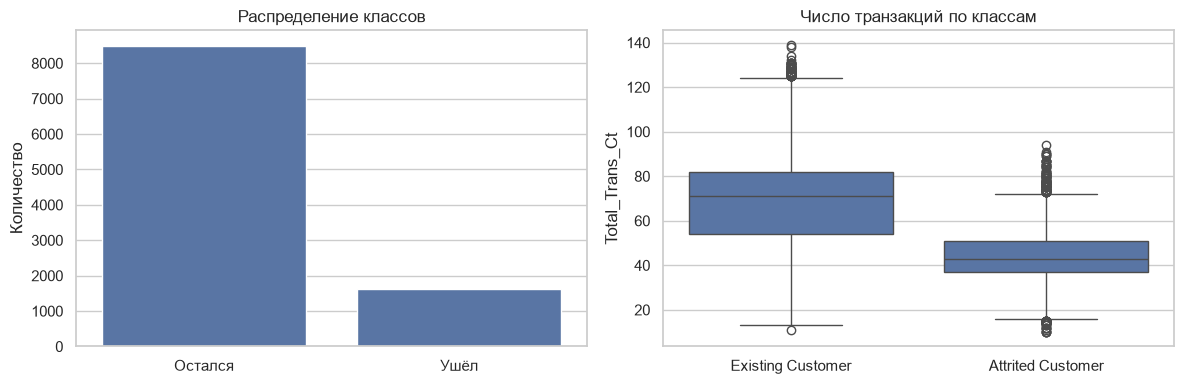

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=y.map({0: 'Остался', 1: 'Ушёл'}), ax=axes[0], order=['Остался', 'Ушёл'])
axes[0].set(title='Распределение классов', xlabel='', ylabel='Количество')
sns.boxplot(data=data, x='Attrition_Flag', y='Total_Trans_Ct', ax=axes[1])
axes[1].set(title='Число транзакций по классам', xlabel='', ylabel='Total_Trans_Ct')
plt.tight_layout()
plt.show()


На левом графике виден дисбаланс: ушедших около 16%. На правом медиана числа транзакций у ушедших — 43, у оставшихся — 71; меньшая активность связана с оттоком, хотя распределения пересекаются.

## 3. Разбиение выборки

Используется стратифицированное разбиение 80/20 с фиксированным `random_state=42`. Тестовая часть откладывается до завершения подбора параметров. Для поиска по сетке применяется стратифицированная трёхкратная кросс-валидация только на обучающей части.


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print('Обучение:', X_train.shape, 'Тест:', X_test.shape)
display(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                      'test': y_test.value_counts(normalize=True)}).rename(index={0: 'остался', 1: 'ушёл'}))
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


Обучение: (8101, 19) Тест: (2026, 19)


,train,test
Attrition_Flag,,
остался,0.839279,0.839585
ушёл,0.160721,0.160415


В обучении 8 101 клиент, в тесте 2 026. Доля ушедших почти одинакова: 16,07% и 16,04%, значит стратификация сохранила состав классов.

## 4. Методы классификации

* **GaussianNB** предполагает нормальное распределение числовых признаков внутри каждого класса.
* **MultinomialNB** и **ComplementNB** работают с неотрицательными признаками; числовые признаки масштабируются в `[0, 1]`. ComplementNB использует статистику дополнения класса и часто полезен при дисбалансе.
* **BernoulliNB** использует бинарные признаки; после масштабирования числовые признаки порогуются.
* **Decision Tree** последовательно делит пространство признаков, используя критерий неоднородности узлов.
* **LDA** моделирует классы с общей ковариационной матрицей и строит линейную границу.
* **SVM** ищет разделяющую границу с максимальным зазором; RBF-ядро допускает нелинейную границу.
* **k-NN** классифицирует по меткам ближайших объектов, поэтому масштаб признаков важен.

Для сопоставимости категориальные признаки кодируются one-hot. Все этапы предобработки находятся в `Pipeline`.


In [10]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

def preprocessor(numeric_steps):
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          *numeric_steps]), numeric_columns),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
         categorical_columns),
    ], sparse_threshold=0)

prep_standard = preprocessor([('scale', StandardScaler())])
prep_nonnegative = preprocessor([('scale', MinMaxScaler())])
prep_binary = preprocessor([('scale', MinMaxScaler()), ('binary', Binarizer(threshold=0.5))])
prep_tree = preprocessor([])

models_and_grids = {
    'GaussianNB': (Pipeline([('prep', prep_standard), ('model', GaussianNB())]),
                   {'model__var_smoothing': [1e-7, 1e-9, 1e-11]}),
    'MultinomialNB': (Pipeline([('prep', prep_nonnegative), ('model', MultinomialNB())]),
                      {'model__alpha': [0.1, 1.0, 10.0]}),
    'ComplementNB': (Pipeline([('prep', prep_nonnegative), ('model', ComplementNB())]),
                     {'model__alpha': [0.1, 1.0, 10.0]}),
    'BernoulliNB': (Pipeline([('prep', prep_binary), ('model', BernoulliNB(binarize=None))]),
                    {'model__alpha': [0.1, 1.0, 10.0]}),
    'Decision Tree': (Pipeline([('prep', prep_tree), ('model', DecisionTreeClassifier(random_state=SEED))]),
                      {'model__max_depth': [4, 8, None],
                       'model__min_samples_leaf': [1, 10],
                       'model__class_weight': [None, 'balanced']}),
    'LDA': (Pipeline([('prep', prep_standard), ('model', LinearDiscriminantAnalysis())]),
            [{'model__solver': ['svd'], 'model__shrinkage': [None]},
             {'model__solver': ['lsqr'], 'model__shrinkage': [None, 'auto', 0.5]}]),
    'SVM': (Pipeline([('prep', prep_standard), ('model', SVC(kernel='rbf'))]),
            {'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.01],
             'model__class_weight': [None, 'balanced']}),
    'k-NN': (Pipeline([('prep', prep_standard), ('model', KNeighborsClassifier())]),
             {'model__n_neighbors': [5, 11, 21], 'model__weights': ['uniform', 'distance'],
              'model__p': [1, 2]}),
}
print('Моделей и вариантов:', len(models_and_grids))


Моделей и вариантов: 8


## 5. Настройка гиперпараметров

Для каждого алгоритма проверяется несколько значений его основных параметров; максимизируется средний ROC-AUC трёх фолдов. `GridSearchCV` обучает весь `Pipeline` заново на каждом фолде. Это исключает подгонку импутации, кодирования и масштабирования на валидационных наблюдениях. Таблица и график ниже фиксируют влияние параметров на кросс-валидационный ROC-AUC; тестовые данные в поиске не участвуют.


In [11]:
searches = {}
cv_tables = []
for name, (pipeline, grid) in models_and_grids.items():
    search = GridSearchCV(pipeline, grid, scoring='roc_auc', cv=cv,
                          n_jobs=2, refit=True, return_train_score=True,
                          error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    result = pd.DataFrame(search.cv_results_)
    result['метод'] = name
    cv_tables.append(result)
    print(f'{name:15s} CV ROC-AUC={search.best_score_:.4f}; параметры={search.best_params_}')

cv_results = pd.concat(cv_tables, ignore_index=True)
experiment_table = cv_results[['метод', 'params', 'mean_train_score',
                               'mean_test_score', 'std_test_score', 'rank_test_score']].copy()
experiment_table = experiment_table.sort_values(['метод', 'rank_test_score'])
display(experiment_table.rename(columns={'params': 'параметры',
                                         'mean_train_score': 'train AUC',
                                         'mean_test_score': 'CV AUC',
                                         'std_test_score': 'CV std'}).round(4))


GaussianNB      CV ROC-AUC=0.8630; параметры={'model__var_smoothing': 1e-07}


MultinomialNB   CV ROC-AUC=0.7835; параметры={'model__alpha': 10.0}


ComplementNB    CV ROC-AUC=0.7835; параметры={'model__alpha': 10.0}


BernoulliNB     CV ROC-AUC=0.8330; параметры={'model__alpha': 1.0}


Decision Tree   CV ROC-AUC=0.9480; параметры={'model__class_weight': None, 'model__max_depth': 8, 'model__min_samples_leaf': 10}


LDA             CV ROC-AUC=0.9227; параметры={'model__shrinkage': None, 'model__solver': 'svd'}


SVM             CV ROC-AUC=0.9658; параметры={'model__C': 10, 'model__class_weight': None, 'model__gamma': 'scale'}


k-NN            CV ROC-AUC=0.9469; параметры={'model__n_neighbors': 21, 'model__p': 1, 'model__weights': 'distance'}


,метод,параметры,train AUC,CV AUC,CV std,rank_test_score
10,BernoulliNB,{'model__alpha': 1.0},0.8382,0.8330,0.0132,1
11,BernoulliNB,{'model__alpha': 10.0},0.8379,0.8328,0.0138,2
9,BernoulliNB,{'model__alpha': 0.1},0.8382,0.8328,0.0130,3
8,ComplementNB,{'model__alpha': 10.0},0.7932,0.7835,0.0188,1
7,ComplementNB,{'model__alpha': 1.0},0.7936,0.7829,0.0177,2
6,ComplementNB,{'model__alpha': 0.1},0.7933,0.7825,0.0175,3
15,Decision Tree,"{'model__class_weight': None, 'model__max_dept...",0.9880,0.9480,0.0095,1
18,Decision Tree,"{'model__class_weight': 'balanced', 'model__ma...",0.9549,0.9468,0.0080,2
19,Decision Tree,"{'model__class_weight': 'balanced', 'model__ma...",0.9556,0.9466,0.0077,3
21,Decision Tree,"{'model__class_weight': 'balanced', 'model__ma...",0.9885,0.9444,0.0087,4


Лучший CV ROC-AUC среди классических моделей получил SVM (0,9658), далее идут дерево (0,9480) и k-NN (0,9469). Полная таблица сохраняет все проверенные комбинации, чтобы сравнение не ограничивалось победителями.

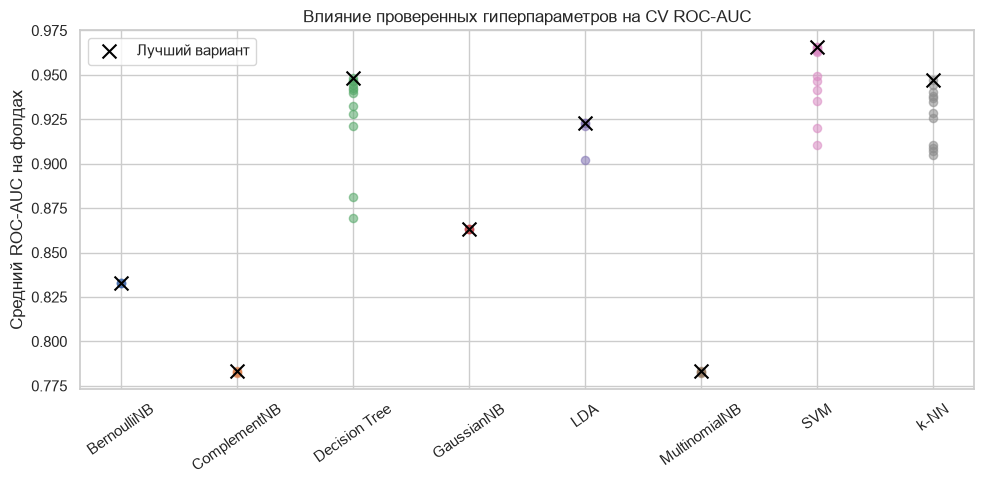

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
for name, sub in experiment_table.groupby('метод'):
    ax.scatter([name] * len(sub), sub['mean_test_score'], alpha=0.55, s=35)
best_cv = experiment_table.loc[experiment_table.groupby('метод')['mean_test_score'].idxmax()]
ax.scatter(best_cv['метод'], best_cv['mean_test_score'], color='black', marker='x', s=100,
           label='Лучший вариант')
ax.set(title='Влияние проверенных гиперпараметров на CV ROC-AUC',
       xlabel='', ylabel='Средний ROC-AUC на фолдах')
ax.tick_params(axis='x', rotation=35)
ax.legend()
plt.tight_layout()
plt.show()


Разброс точек показывает чувствительность к гиперпараметрам: у SVM CV ROC-AUC менялся примерно от 0,911 до 0,966, у дерева — от 0,870 до 0,948. У вариантов GaussianNB различий почти нет (около 0,863).

In [13]:
gaps = best_cv[['метод', 'mean_train_score', 'mean_test_score']].copy()
gaps['разрыв train − CV'] = gaps['mean_train_score'] - gaps['mean_test_score']
display(gaps.set_index('метод').round(4))


,mean_train_score,mean_test_score,разрыв train − CV
метод,,,
BernoulliNB,0.8382,0.8330,0.0053
ComplementNB,0.7932,0.7835,0.0097
Decision Tree,0.9880,0.9480,0.0400
GaussianNB,0.8694,0.8630,0.0064
LDA,0.9253,0.9227,0.0026
MultinomialNB,0.7932,0.7835,0.0097
SVM,0.9979,0.9658,0.0320
k-NN,1.0000,0.9469,0.0531


У лучшего k-NN разрыв между обучением и CV равен 0,053, у дерева — 0,040, у SVM — 0,032. Эти методы сильнее подстраиваются под обучающие данные, чем LDA (разрыв 0,003).

### Интерпретация подбора параметров (запуск с seed 42)

* **Дерево решений:** неограниченная глубина с листьями из одного объекта дала train ROC-AUC 1,000, но CV ROC-AUC около 0,881 — признак переобучения. Ограничения глубины и минимального размера листа подняли лучший CV ROC-AUC до 0,948.
* **SVM:** изменение `C`, `gamma` и весов классов заметно влияло на качество: проверенные варианты дали CV ROC-AUC примерно от 0,911 до 0,966. Лучший результат среди классических методов получен у SVM.
* **k-NN:** в этой сетке увеличение числа соседей с 5 до 21 подняло лучший CV ROC-AUC примерно с 0,911 до 0,947. Это указывает на шумность оценки по слишком малому числу соседей.
* **LDA и Naive Bayes:** изменение проверенных параметров влияло на CV ROC-AUC значительно слабее. У GaussianNB все три значения `var_smoothing` дали около 0,863. Для MultinomialNB и ComplementNB изменение `alpha` дало менее 0,002 ROC-AUC.

Эти выводы относятся к заданным сеткам параметров и одному разбиению; они не доказывают оптимальность параметров вне проверенных диапазонов.


In [14]:
def evaluate_predictions(y_true, y_pred, y_score):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred, zero_division=0),
            'F1': f1_score(y_true, y_pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y_true, y_score)}

rows = []
roc_data = {}
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_score = dummy.predict_proba(X_test)[:, 1]
rows.append({'Метод': 'Baseline: большинство', **evaluate_predictions(y_test, dummy_pred, dummy_score)})
roc_data['Baseline: большинство'] = dummy_score

for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)
    score = (model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba')
             else model.decision_function(X_test))
    rows.append({'Метод': name, **evaluate_predictions(y_test, pred, score)})
    roc_data[name] = score

classical_metrics = pd.DataFrame(rows).set_index('Метод')
display(classical_metrics.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC
Метод,,,,,
Baseline: большинство,0.8396,0.0000,0.0000,0.0000,0.5000
GaussianNB,0.8712,0.6067,0.5600,0.5824,0.8361
MultinomialNB,0.8396,0.0000,0.0000,0.0000,0.7577
ComplementNB,0.7354,0.3359,0.6646,0.4463,0.7577
BernoulliNB,0.8425,0.5181,0.2646,0.3503,0.7958
Decision Tree,0.9358,0.8176,0.7723,0.7943,0.9482
LDA,0.9013,0.7551,0.5692,0.6491,0.9135
SVM,0.9353,0.8255,0.7569,0.7897,0.9648
k-NN,0.8978,0.8512,0.4400,0.5801,0.9368


На тесте SVM показал лучший классический ROC-AUC 0,9648; дерево — лучший классический F1 0,7943. MultinomialNB при стандартном пороге не нашёл ушедших клиентов (recall 0), несмотря на accuracy 0,8396, равную базовой модели.

## 6. Нейронная сеть на TensorFlow

**Архитектура:** полносвязные скрытые слои `Dense` с ReLU или tanh, выходной нейрон `Dense(1, sigmoid)`. **Функция потерь:** binary cross-entropy. **Оптимизатор:** Adam. В восьми запусках меняются число и ширина слоёв, активация, размер батча и максимальное число эпох. Ранняя остановка восстанавливает веса лучшей эпохи по `val_loss`.

Из обучающей части выделяется отдельная стратифицированная валидационная часть (20% от train). Её используют для сравнения конфигураций сети; тестовая часть остаётся нетронутой до выбора сети. Из-за дисбаланса классов при обучении применяются веса классов. TensorBoard сохраняет `loss`, `accuracy`, `val_loss`, `val_accuracy` и граф модели во временную папку с латинским путём: это необходимо для совместимости TensorFlow с Windows, когда путь к notebook содержит кириллицу.


In [15]:
import tensorflow as tf
import tempfile
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as exc:
    print('Полная детерминированность недоступна:', exc)

X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=SEED)

nn_preprocessor = clone(prep_standard)
X_nn_train_arr = nn_preprocessor.fit_transform(X_nn_train).astype('float32')
X_nn_val_arr = nn_preprocessor.transform(X_nn_val).astype('float32')
X_nn_test_arr = nn_preprocessor.transform(X_test).astype('float32')
class_values = np.array([0, 1])
weights = compute_class_weight('balanced', classes=class_values, y=y_nn_train)
class_weight = dict(zip(class_values.tolist(), weights.tolist()))
print('Размер входа сети:', X_nn_train_arr.shape[1])
print('Веса классов:', class_weight)


Размер входа сети: 34
Веса классов: {0: 0.5956977385548814, 1: 3.112391930835735}


In [16]:
def build_network(input_dim, hidden_layers=(64, 32), activation='relu', learning_rate=1e-3):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(input_dim,))])
    for units in hidden_layers:
        model.add(tf.keras.layers.Dense(units, activation=activation))
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

experiments = [
    {'name': '1x32_relu_b32_e20', 'hidden_layers': (32,), 'activation': 'relu',
     'batch_size': 32, 'epochs': 20},
    {'name': '2x64_32_relu_b64_e30', 'hidden_layers': (64, 32), 'activation': 'relu',
     'batch_size': 64, 'epochs': 30},
    {'name': '2x64_32_tanh_b64_e30', 'hidden_layers': (64, 32), 'activation': 'tanh',
     'batch_size': 64, 'epochs': 30},
    {'name': '3x64_32_16_relu_b128_e40', 'hidden_layers': (64, 32, 16), 'activation': 'relu',
     'batch_size': 128, 'epochs': 40},
    # Четыре контрольных запуска: каждый отличается от 2x64_32_relu_b64_e30 одним параметром.
    {'name': '2x64_32_relu_b64_e10', 'hidden_layers': (64, 32), 'activation': 'relu',
     'batch_size': 64, 'epochs': 10},
    {'name': '2x64_32_relu_b32_e30', 'hidden_layers': (64, 32), 'activation': 'relu',
     'batch_size': 32, 'epochs': 30},
    {'name': '1x64_relu_b64_e30', 'hidden_layers': (64,), 'activation': 'relu',
     'batch_size': 64, 'epochs': 30},
    {'name': '2x32_16_relu_b64_e30', 'hidden_layers': (32, 16), 'activation': 'relu',
     'batch_size': 64, 'epochs': 30},
]

log_root = Path(tempfile.gettempdir()) / 'lab2_credit_card_tensorboard'
log_root.mkdir(parents=True, exist_ok=True)
print('TensorBoard logs:', log_root)
nn_models = {}
nn_histories = {}
nn_rows = []
for i, config in enumerate(experiments):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_network(X_nn_train_arr.shape[1], config['hidden_layers'], config['activation'])
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6,
                                         restore_best_weights=True),
        tf.keras.callbacks.TensorBoard(log_dir=str(log_root / config['name']),
                                       histogram_freq=1, update_freq='epoch'),
    ]
    history = model.fit(X_nn_train_arr, y_nn_train.to_numpy(),
                        validation_data=(X_nn_val_arr, y_nn_val.to_numpy()),
                        batch_size=config['batch_size'], epochs=config['epochs'],
                        class_weight=class_weight, callbacks=callbacks, verbose=0)
    val_score = model.predict(X_nn_val_arr, verbose=0).ravel()
    val_pred = (val_score >= 0.5).astype(int)
    nn_rows.append({'Конфигурация': config['name'], 'Слои': str(config['hidden_layers']),
                    'Активация': config['activation'], 'Batch': config['batch_size'],
                    'Макс. эпох': config['epochs'], 'Факт. эпох': len(history.history['loss']),
                    **evaluate_predictions(y_nn_val, val_pred, val_score)})
    nn_models[config['name']] = model
    nn_histories[config['name']] = history.history
    print(f"{config['name']}: эпох={len(history.history['loss'])}, "
          f"val ROC-AUC={nn_rows[-1]['ROC-AUC']:.4f}, val F1={nn_rows[-1]['F1']:.4f}")

nn_experiment_table = pd.DataFrame(nn_rows).sort_values('ROC-AUC', ascending=False)
display(nn_experiment_table.round(4))


TensorBoard logs: C:\Users\shipu\AppData\Local\Temp\lab2_credit_card_tensorboard


1x32_relu_b32_e20: эпох=20, val ROC-AUC=0.9635, val F1=0.7662



2x64_32_relu_b64_e30: эпох=27, val ROC-AUC=0.9641, val F1=0.7837


2x64_32_tanh_b64_e30: эпох=30, val ROC-AUC=0.9750, val F1=0.8083


3x64_32_16_relu_b128_e40: эпох=32, val ROC-AUC=0.9621, val F1=0.7558


2x64_32_relu_b64_e10: эпох=10, val ROC-AUC=0.9621, val F1=0.7755


2x64_32_relu_b32_e30: эпох=19, val ROC-AUC=0.9642, val F1=0.7681


1x64_relu_b64_e30: эпох=30, val ROC-AUC=0.9641, val F1=0.7804


2x32_16_relu_b64_e30: эпох=30, val ROC-AUC=0.9663, val F1=0.7782


,Конфигурация,Слои,Активация,Batch,Макс. эпох,Факт. эпох,Accuracy,Precision,Recall,F1,ROC-AUC
2,2x64_32_tanh_b64_e30,"(64, 32)",tanh,64,30,30,0.9315,0.7358,0.8966,0.8083,0.9750
7,2x32_16_relu_b64_e30,"(32, 16)",relu,64,30,30,0.9198,0.7015,0.8736,0.7782,0.9663
5,2x64_32_relu_b32_e30,"(64, 32)",relu,32,30,19,0.9229,0.7446,0.7931,0.7681,0.9642
6,1x64_relu_b64_e30,"(64,)",relu,64,30,30,0.9198,0.6979,0.8851,0.7804,0.9641
1,2x64_32_relu_b64_e30,"(64, 32)",relu,64,30,27,0.9247,0.7294,0.8467,0.7837,0.9641
0,1x32_relu_b32_e20,"(32,)",relu,32,20,20,0.9130,0.6754,0.8851,0.7662,0.9635
4,2x64_32_relu_b64_e10,"(64, 32)",relu,64,10,10,0.9186,0.6972,0.8736,0.7755,0.9621
3,3x64_32_16_relu_b128_e40,"(64, 32, 16)",relu,128,40,32,0.9155,0.7067,0.8123,0.7558,0.9621


На валидации лучшей оказалась сеть с двумя слоями `(64, 32)`, `tanh`, batch 64 и максимумом 30 эпох: ROC-AUC 0,9750, F1 0,8083, recall 0,8966. Остальные семь конфигураций дали ROC-AUC от 0,9621 до 0,9663. Выбор сделан до проверки на тестовой выборке.

In [17]:
# Сравнение с опорной конфигурацией: меняется ровно один параметр.
baseline_nn = '2x64_32_relu_b64_e30'
effect_pairs = [
    ('Эпохи: 30 → 10', '2x64_32_relu_b64_e10'),
    ('Batch: 64 → 32', '2x64_32_relu_b32_e30'),
    ('Слои: (64, 32) → (64,)', '1x64_relu_b64_e30'),
    ('Нейроны: (64, 32) → (32, 16)', '2x32_16_relu_b64_e30'),
    ('Активация: ReLU → tanh', '2x64_32_tanh_b64_e30'),
]
nn_indexed = nn_experiment_table.set_index('Конфигурация')
baseline_auc = nn_indexed.loc[baseline_nn, 'ROC-AUC']
effect_rows = []
for parameter, variant in effect_pairs:
    variant_auc = nn_indexed.loc[variant, 'ROC-AUC']
    effect_rows.append({'Изменённый параметр': parameter, 'Базовый ROC-AUC': baseline_auc,
                        'ROC-AUC варианта': variant_auc, 'Разница': variant_auc - baseline_auc})
effect_table = pd.DataFrame(effect_rows)
display(effect_table.round(4))


,Изменённый параметр,Базовый ROC-AUC,ROC-AUC варианта,Разница
0,Эпохи: 30 → 10,0.9641,0.9621,-0.0020
1,Batch: 64 → 32,0.9641,0.9642,0.0001
2,"Слои: (64, 32) → (64,)",0.9641,0.9641,0.0000
3,"Нейроны: (64, 32) → (32, 16)",0.9641,0.9663,0.0022
4,Активация: ReLU → tanh,0.9641,0.9750,0.0109


Самое заметное улучшение относительно базовой ReLU-сети с ROC-AUC 0,9641 дала замена активации на `tanh`: **+0,0109**. Сокращение обучения с 30 до 10 эпох снизило ROC-AUC на 0,0020; уменьшение ширины слоёв добавило 0,0022. Уменьшение batch с 64 до 32 и удаление второго слоя почти не изменили ROC-AUC (разница 0,0001 и менее 0,0001). Каждый вариант отличается от базы только одним указанным параметром; seed одинаковый.

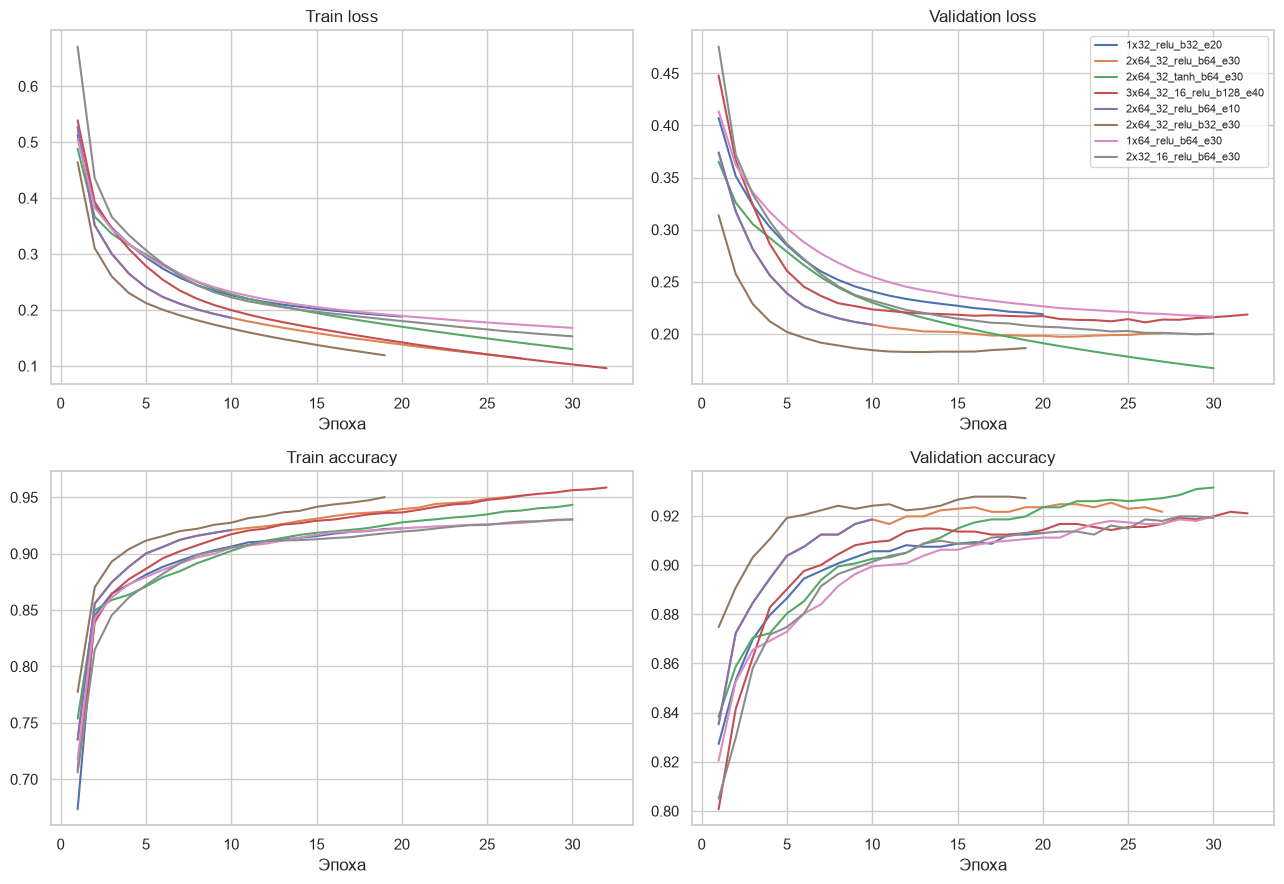

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for name, history in nn_histories.items():
    epochs_axis = np.arange(1, len(history['loss']) + 1)
    axes[0, 0].plot(epochs_axis, history['loss'], label=name)
    axes[0, 1].plot(epochs_axis, history['val_loss'], label=name)
    axes[1, 0].plot(epochs_axis, history['accuracy'], label=name)
    axes[1, 1].plot(epochs_axis, history['val_accuracy'], label=name)
for ax, title in zip(axes.flat, ['Train loss', 'Validation loss',
                                  'Train accuracy', 'Validation accuracy']):
    ax.set(title=title, xlabel='Эпоха')
axes[0, 1].legend(loc='best', fontsize=8)
plt.tight_layout()
plt.show()


Во всех восьми запусках train loss снижается, а train accuracy растёт. У сети с `tanh` к 30-й эпохе validation loss достигает около 0,17, validation accuracy — около 0,93. У трёхслойной ReLU-сети train loss продолжает падать примерно до 0,10, тогда как validation loss держится около 0,22: появляется разрыв между обучением и валидацией. Базовый ReLU-запуск остановлен на 27-й эпохе, трёхслойный — на 32-й, вариант с batch 32 — на 19-й благодаря EarlyStopping.

### TensorBoard

В Jupyter откройте следующий блок после обучения. В TensorBoard выберите вкладку **Scalars** и сравните восемь запусков по `loss`, `accuracy`, `val_loss`, `val_accuracy`. Путь к журналам напечатан в ячейке обучения.


In [5]:
import os
import sys
import shutil
from pathlib import Path

binary_candidates = [
    Path(sys.executable).with_name('tensorboard.exe'),
    Path(sys.executable).parent / 'Scripts' / 'tensorboard.exe',
]
tensorboard_binary = next((p for p in binary_candidates if p.is_file()), None)
if tensorboard_binary is None:
    found = shutil.which('tensorboard')
    tensorboard_binary = Path(found) if found else None
if tensorboard_binary is None:
    raise FileNotFoundError('TensorBoard не найден в текущем ядре. Выполните %pip install tensorboard и повторите ячейку.')
os.environ['TENSORBOARD_BINARY'] = str(tensorboard_binary)

%load_ext tensorboard
log_dir = log_root.as_posix()
%tensorboard --logdir $log_dir


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


TensorBoard сохраняет журналы всех восьми запусков и показывает, как по эпохам менялись train/validation `loss` и `accuracy`. Из этих кривых видно, почему продолжать обучение после стабилизации валидации не всегда полезно; итоговая конфигурация выбрана по отдельному validation ROC-AUC.

На скриншотах наложены кривые повторных запусков из одной папки журналов. Для сравнения конкретных конфигураций используем таблицу экспериментов выше.

#### epoch_accuracy

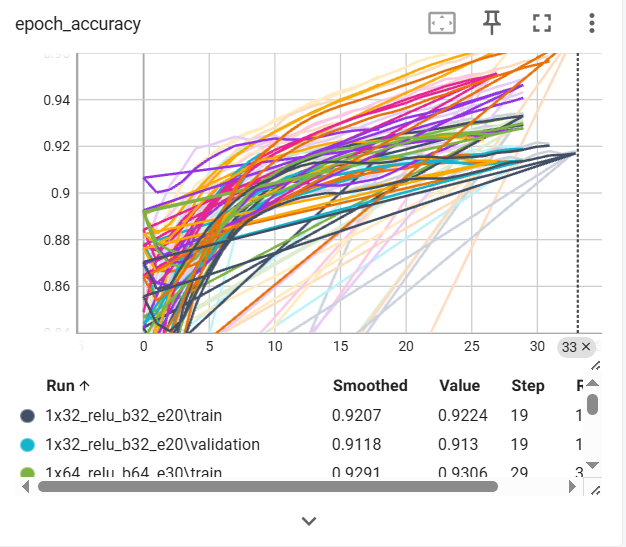

Точность обучения и валидации в большинстве запусков растёт по эпохам. Для конфигурации `1x32_relu_b32_e20` на 19-й эпохе показаны train accuracy 0,9224 и validation accuracy 0,9130; небольшой разрыв указывает, что результат на валидации немного ниже обучающего.

#### epoch_loss

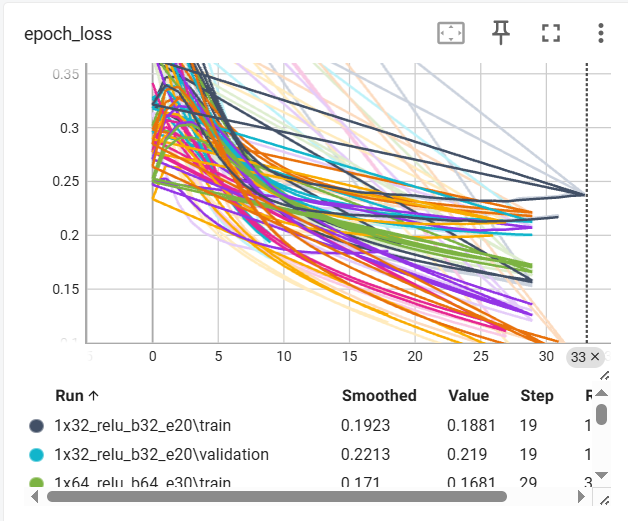

Потери быстрее всего снижаются в первые эпохи, затем уменьшение замедляется. Для `1x32_relu_b32_e20` на 19-й эпохе train loss равен 0,1881, validation loss — 0,2190: на валидации ошибка выше, чем на обучении.

#### evaluation_accuracy_vs_iterations

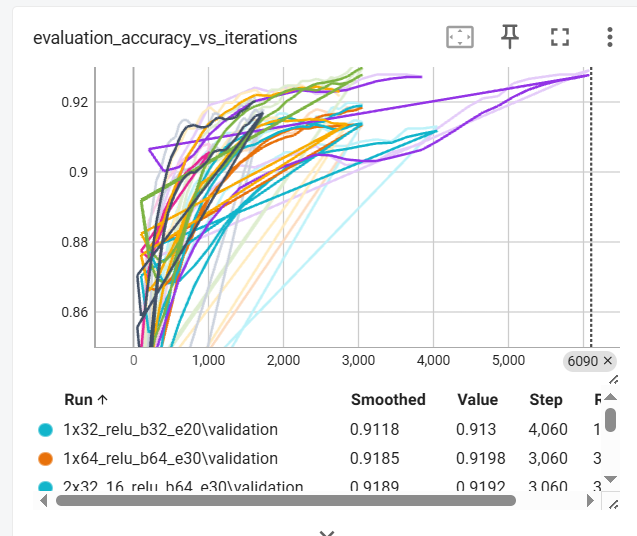

Валидационная accuracy растёт по мере обновления весов и у многих запусков выходит примерно на 0,90–0,93 после нескольких тысяч итераций. На показанных строках `1x32_relu_b32_e20` достигает 0,9130 к 4 060 итерациям, а `1x64_relu_b64_e30` — 0,9198 к 3 060 итерациям; поздний прирост становится небольшим.

#### evaluation_loss_vs_iterations

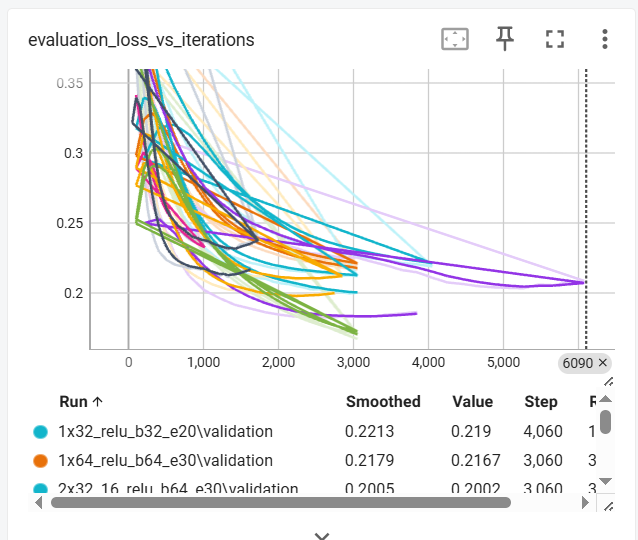

Валидационная потеря в целом падает примерно с 0,30–0,35 до диапазона 0,17–0,22, после чего у части кривых выходит на плато или слегка растёт. Например, на показанных строках значения 0,2190 и 0,2167 получены к 4 060 и 3 060 итерациям соответственно. Это поддерживает применение ранней остановки вместо обучения до произвольно большого числа шагов.

In [20]:
best_nn_name = nn_experiment_table.iloc[0]['Конфигурация']
best_nn = nn_models[best_nn_name]
nn_score = best_nn.predict(X_nn_test_arr, verbose=0).ravel()
nn_pred = (nn_score >= 0.5).astype(int)
nn_metrics = evaluate_predictions(y_test, nn_pred, nn_score)
roc_data['TensorFlow NN'] = nn_score
print('Лучшая сеть по validation ROC-AUC:', best_nn_name)
print('Её метрики на отложенном тесте:')
display(pd.DataFrame([nn_metrics], index=['TensorFlow NN']).round(4))


Лучшая сеть по validation ROC-AUC: 2x64_32_tanh_b64_e30
Её метрики на отложенном тесте:


,Accuracy,Precision,Recall,F1,ROC-AUC
TensorFlow NN,0.9284,0.7381,0.8585,0.7937,0.9697


Выбранная по валидации сеть получила на отложенном тесте ROC-AUC **0,9697**, recall **0,8585**, F1 **0,7937**. Тестовый ROC-AUC ниже валидационного 0,9750 на 0,0053, но остаётся наивысшим среди сравниваемых методов в этом запуске.

## 7. Сравнительный анализ

В таблице все методы проверяются на **одной и той же** тестовой выборке. Базовый классификатор всегда предсказывает большинство и показывает, насколько содержательны полученные результаты. ROC-AUC оценивает ранжирование по всем порогам, а precision/recall/F1 ниже вычислены при стандартном пороге решения (для сети — 0.5). Для SVM в ROC-AUC используется значение `decision_function`.


Здесь `TP` — верно найденные ушедшие клиенты, `FP` — ложные тревоги, `FN` — пропущенные ушедшие, `TN` — верно найденные оставшиеся. `Accuracy = (TP + TN) / N`, `Precision = TP / (TP + FP)`, `Recall = TP / (TP + FN)`, `F1 = 2 · Precision · Recall / (Precision + Recall)`. ROC-AUC — площадь под ROC-кривой по всем порогам.


In [21]:
all_metrics = pd.concat([
    classical_metrics,
    pd.DataFrame([nn_metrics], index=pd.Index(['TensorFlow NN'], name='Метод'))
]).sort_values('ROC-AUC', ascending=False)
display(all_metrics.round(4))


,Accuracy,Precision,Recall,F1,ROC-AUC
Метод,,,,,
TensorFlow NN,0.9284,0.7381,0.8585,0.7937,0.9697
SVM,0.9353,0.8255,0.7569,0.7897,0.9648
Decision Tree,0.9358,0.8176,0.7723,0.7943,0.9482
k-NN,0.8978,0.8512,0.4400,0.5801,0.9368
LDA,0.9013,0.7551,0.5692,0.6491,0.9135
GaussianNB,0.8712,0.6067,0.5600,0.5824,0.8361
BernoulliNB,0.8425,0.5181,0.2646,0.3503,0.7958
MultinomialNB,0.8396,0.0000,0.0000,0.0000,0.7577
ComplementNB,0.7354,0.3359,0.6646,0.4463,0.7577


Нейронная сеть лидирует по ROC-AUC (0,9697) и recall ушедших клиентов (0,8585). Дерево и сеть почти равны по F1 (0,7943 и 0,7937); у SVM выше precision, чем у сети (0,8255 против 0,7381).

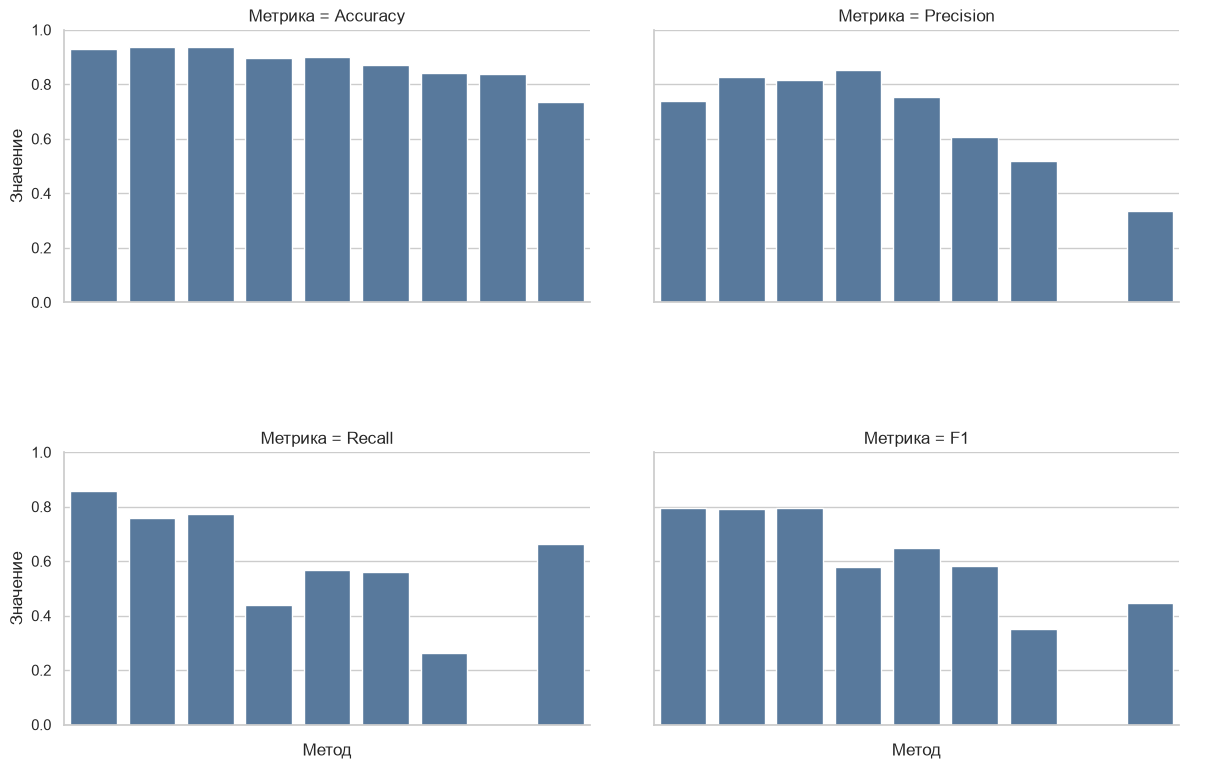

In [22]:
plot_data = all_metrics.drop(index='Baseline: большинство').reset_index().melt(
    id_vars='Метод', value_vars=['Accuracy', 'Precision', 'Recall', 'F1'],
    var_name='Метрика', value_name='Значение')
g = sns.catplot(data=plot_data, x='Метод', y='Значение', col='Метрика',
                kind='bar', col_wrap=2, sharey=True, height=4, aspect=1.5,
                color='#4C78A8')
g.set_xticklabels(rotation=55, ha='right')
g.set(ylim=(0, 1))
g.fig.subplots_adjust(hspace=0.55)
plt.show()


k-NN даёт максимальную precision 0,8512, но находит лишь 44% ушедших клиентов. Сеть находит 85,85% и при этом имеет precision 0,7381. Высокая accuracy MultinomialNB (0,8396) не помогает задаче оттока: recall равен нулю.

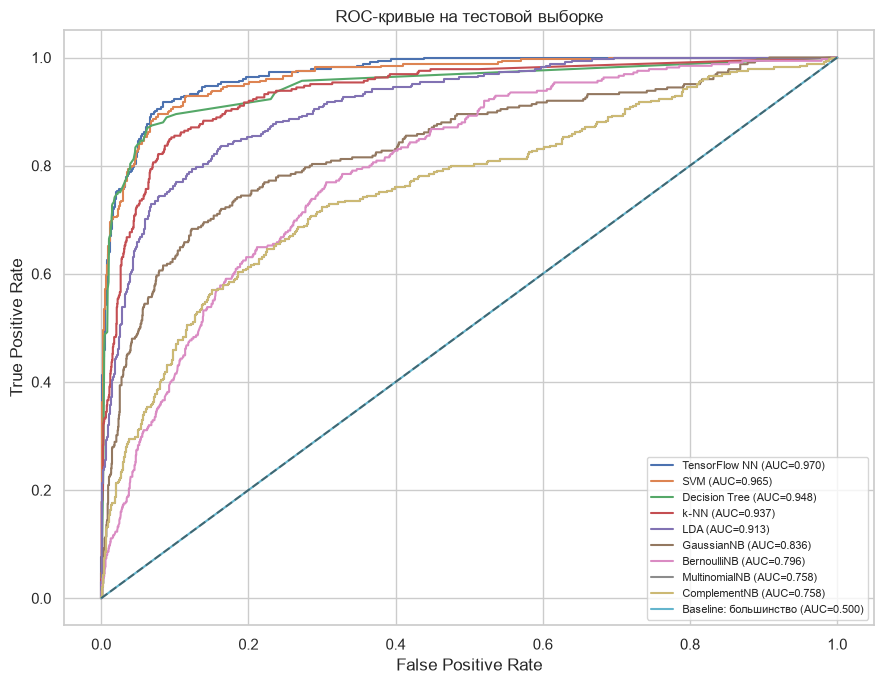

In [23]:
fig, ax = plt.subplots(figsize=(9, 7))
for name in all_metrics.index:
    fpr, tpr, _ = roc_curve(y_test, roc_data[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC={all_metrics.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set(title='ROC-кривые на тестовой выборке', xlabel='False Positive Rate',
       ylabel='True Positive Rate')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()


Наибольшая площадь под ROC-кривой у сети — 0,9697; следующий результат у SVM — 0,9648. Базовая модель имеет AUC 0,5, что соответствует отсутствию способности ранжировать клиентов по риску.

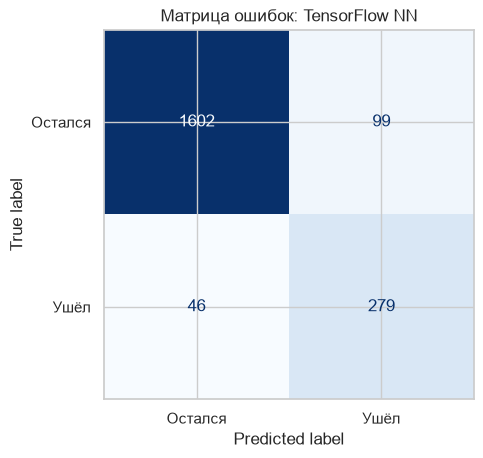

In [24]:
best_method_name = all_metrics.drop(index='Baseline: большинство')['ROC-AUC'].idxmax()
best_pred = (nn_pred if best_method_name == 'TensorFlow NN'
             else searches[best_method_name].best_estimator_.predict(X_test))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred,
    display_labels=['Остался', 'Ушёл'], cmap='Blues', colorbar=False)
plt.title(f'Матрица ошибок: {best_method_name}')
plt.show()


Для выбранной сети на тесте: 279 верно найденных ушедших клиентов, 46 пропущенных, 99 ложных тревог и 1 602 верно распознанных оставшихся. Сеть находит большинство ушедших клиентов, но примерно каждое четвёртое предупреждение о риске оттока ложно.

Лучший классический метод по тестовому ROC-AUC: SVM (0.9648)
Нейронная сеть: ROC-AUC=0.9697, F1=0.7937, Recall=0.8585
Максимальный тестовый ROC-AUC: TensorFlow NN (0.9697)
При выборе для практики также учитывайте Recall и Precision для класса «ушёл».

## 8. Заключение

Подготовлены данные о 10 127 клиентах, исключены идентификатор и готовые предсказания из исходного CSV. Проведены стратифицированное разбиение, подбор параметров восьми классических моделей и восемь экспериментов с полносвязной сетью TensorFlow. В пяти контрольных сравнениях по одному менялись эпохи, batch, число слоёв, ширина слоёв и активация. Все итоговые метрики измерены на одной отложенной тестовой выборке.

**Лучший подход для обнаружения оттока в этом запуске — нейронная сеть** с двумя скрытыми слоями (64 и 32 нейрона, `tanh`, batch 64): тестовый ROC-AUC **0,9697** и recall ушедших клиентов **0,8585**. Она находит больше ушедших клиентов, чем SVM (recall 0,7569), и лучше ранжирует клиентов по риску (ROC-AUC SVM 0,9648). Цена более высокой полноты — меньшая precision: 0,7381 у сети против 0,8255 у SVM. Если ложные тревоги особенно дороги, SVM или подбор другого порога решения может оказаться предпочтительнее.

По F1 дерево решений (0,7943) и сеть (0,7937) практически равны в рамках этого теста. Наивысшая accuracy у дерева (0,9358), но из-за дисбаланса классов она не является достаточным основанием для выбора. Модель большинства достигает accuracy 0,8396, при этом не находит ни одного ушедшего клиента.

**Ограничения:** использованы одно разбиение и один отложенный тест, поэтому малые различия между моделями нельзя считать устойчивыми без повторных разбиений или внешней проверки. Рабочий порог для банка следует выбирать отдельно с учётом стоимости пропущенного оттока и ложных тревог. 
